# DS-A2 | Inference and Uncertainty Notebook

**Study type:** simulation-only; all observations are synthetic. This notebook is a reproducible working project. After execution, inspect every output and write your own interpretation in the report and submission summary.

## 1. Pre-registration and estimand
**Question:** How do sample size, noise, and true mean difference affect estimation uncertainty and the probability of detecting a difference between two independent groups?

**Unit:** one simulated observation. **Estimand:** Δ = μB − μA. **Null:** H₀: Δ = 0. **Alternative:** H₁: Δ ≠ 0. **Significance level:** α = 0.05. **Minimum meaningful effect (provisional):** 0.3 standard deviations; explain whether this threshold is meaningful for your intended context before interpreting results.

**Baseline model:** independent normal observations with common standard deviation σ; group A has mean 0 and group B has mean Δ. **Primary inference:** Welch two-sample t interval/test. **Resampling check:** percentile bootstrap interval. **Power:** fraction of simulated tests rejecting H₀. **Counterexample:** heavy-tailed observations (Student-t errors) violate normality and test the robustness of the chosen procedure.

**Provenance:** synthetic data generated in code; no external dataset is used. A fixed seed makes the simulation reproducible, but results depend on the specified data-generating process.

In [1]:
import sys, platform, json, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib.pyplot as plt

SEED = 20261014
ALPHA = 0.05
N_REPS = 3000
BOOT_REPS = 4000
rng = np.random.default_rng(SEED)
ROOT = Path('..')
FIG_DIR, RES_DIR = ROOT/'figures', ROOT/'results'
FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR.mkdir(parents=True, exist_ok=True)
print('Python:', sys.version.split()[0])
print('Platform:', platform.platform())
print('NumPy:', np.__version__, '| pandas:', pd.__version__, '| SciPy:', scipy.__version__)
print('Matplotlib:', plt.matplotlib.__version__, '| seed:', SEED)
print('Repetitions:', N_REPS, '| bootstrap draws:', BOOT_REPS)

Python: 3.13.5
Platform: Linux-6.18.44-x86_64-with-glibc2.41
NumPy: 2.3.5 | pandas: 2.2.3 | SciPy: 1.17.0
Matplotlib: 3.10.8 | seed: 20261014
Repetitions: 3000 | bootstrap draws: 4000


## 2. Data-generating process and method note
For each replicate, generate independent samples Aᵢ ~ Normal(0, σ²) and Bᵢ ~ Normal(Δ, σ²). The estimator is Δ̂ = mean(B) − mean(A). Welch's standard error is √(s²A/nA + s²B/nB); its degrees of freedom use the Welch–Satterthwaite approximation. A two-sided 95% confidence interval is Δ̂ ± t* SE, and the test p-value is from Welch's t statistic. The bootstrap resamples each observed group independently with replacement and uses the 2.5th and 97.5th percentiles of bootstrap differences.

In [2]:
def simulate_two_groups(n, effect, sigma=1.0, rng=None, distribution='normal'):
    """Generate independent samples A and B; B's location is shifted by effect."""
    if n < 2 or sigma <= 0:
        raise ValueError('n must be >= 2 and sigma must be positive')
    rng = np.random.default_rng(SEED) if rng is None else rng
    if distribution == 'normal':
        a = rng.normal(0, sigma, n)
        b = rng.normal(effect, sigma, n)
    elif distribution == 'heavy_tailed':
        # t(df=3) has finite variance; scale to requested standard deviation.
        scale = sigma / np.sqrt(3/(3-2))
        a = rng.standard_t(df=3, size=n) * scale
        b = effect + rng.standard_t(df=3, size=n) * scale
    else:
        raise ValueError("distribution must be 'normal' or 'heavy_tailed'")
    return a, b

def mean_difference_ci_welch(a, b, confidence=0.95):
    """Return estimate, CI lower/upper, and two-sided Welch p-value."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    estimate = float(np.mean(b) - np.mean(a))
    va, vb = np.var(a, ddof=1), np.var(b, ddof=1)
    se2 = va/len(a) + vb/len(b)
    se = np.sqrt(se2)
    df = se2**2 / ((va/len(a))**2/(len(a)-1) + (vb/len(b))**2/(len(b)-1))
    tcrit = stats.t.ppf((1+confidence)/2, df)
    tstat = estimate/se
    p = float(2*stats.t.sf(abs(tstat), df))
    return estimate, float(estimate-tcrit*se), float(estimate+tcrit*se), p

def bootstrap_mean_difference_ci(a, b, n_boot=BOOT_REPS, confidence=0.95, seed=SEED):
    """Return estimate and percentile bootstrap CI for mean(B)-mean(A)."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    brng = np.random.default_rng(seed)
    estimates = np.empty(n_boot)
    for i in range(n_boot):
        aa = brng.choice(a, size=len(a), replace=True)
        bb = brng.choice(b, size=len(b), replace=True)
        estimates[i] = bb.mean() - aa.mean()
    tail = (1-confidence)/2
    return float(b.mean()-a.mean()), float(np.quantile(estimates, tail)), float(np.quantile(estimates, 1-tail))

## 3. Baseline estimate and interval comparison
The baseline scenario uses n = 40 per group, Δ = 0.3 and σ = 1.0. This is a single random realization, so its estimate and p-value need not equal the population values. Compare the Welch and bootstrap intervals; they are different methods and need not match exactly.

In [3]:
base_rng = np.random.default_rng(SEED + 1)
a, b = simulate_two_groups(n=40, effect=0.3, sigma=1.0, rng=base_rng)
est, lo, hi, pval = mean_difference_ci_welch(a, b)
best, blo, bhi = bootstrap_mean_difference_ci(a, b, n_boot=BOOT_REPS, seed=SEED+2)
baseline = pd.DataFrame([
    {'method':'Welch t interval/test','estimate':est,'ci_lower':lo,'ci_upper':hi,'p_value':pval},
    {'method':'Percentile bootstrap interval','estimate':best,'ci_lower':blo,'ci_upper':bhi,'p_value':np.nan},
])
baseline.to_csv(RES_DIR/'baseline_inference.csv', index=False)
display(baseline)
print('True population difference:', 0.3)
print('Interpretation prompt: Is the estimated effect close to 0.3? Does each interval include zero? What does that imply, and what does it not imply?')

,method,estimate,ci_lower,ci_upper,p_value
0,Welch t interval/test,0.230197,-0.186402,0.646796,0.274548
1,Percentile bootstrap interval,0.230197,-0.175334,0.634642,NaN


True population difference: 0.3
Interpretation prompt: Is the estimated effect close to 0.3? Does each interval include zero? What does that imply, and what does it not imply?


## 4. Sampling distribution
Repeat the baseline experiment 3,000 times and record the mean-difference estimator. The figure is a Monte Carlo approximation to the estimator's sampling distribution under the assumed normal model.

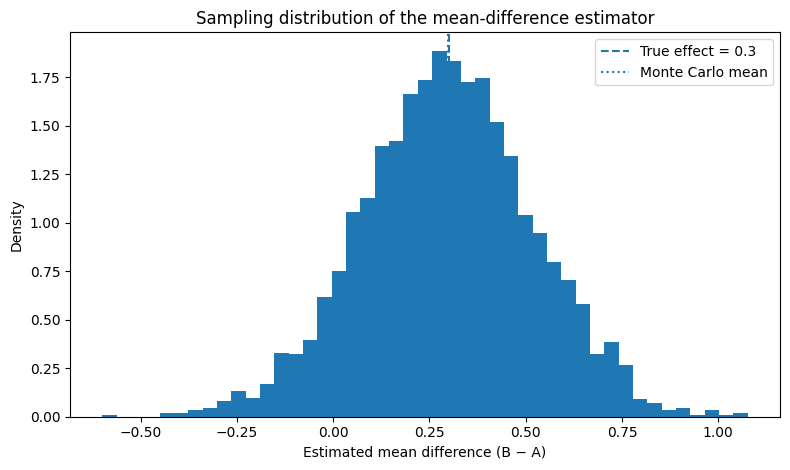

,replications,true_effect,mean_estimate,bias_estimate,empirical_sd,theoretical_se
0,3000,0.3,0.297096,-0.002904,0.222714,0.223607


Interpretation prompt: Discuss the center, spread, possible Monte Carlo bias, and agreement between empirical and theoretical standard error.


In [4]:
sampling_rng = np.random.default_rng(SEED + 10)
sampling_estimates = np.empty(N_REPS)
for i in range(N_REPS):
    aa, bb = simulate_two_groups(40, effect=0.3, sigma=1.0, rng=sampling_rng)
    sampling_estimates[i] = bb.mean() - aa.mean()
sampling_summary = pd.DataFrame([{
    'replications': N_REPS, 'true_effect': 0.3,
    'mean_estimate': sampling_estimates.mean(),
    'bias_estimate': sampling_estimates.mean()-0.3,
    'empirical_sd': sampling_estimates.std(ddof=1),
    'theoretical_se': np.sqrt(2/40)
}])
sampling_summary.to_csv(RES_DIR/'sampling_distribution_summary.csv', index=False)
plt.figure(figsize=(8,4.8))
plt.hist(sampling_estimates, bins=45, density=True)
plt.axvline(0.3, linestyle='--', label='True effect = 0.3')
plt.axvline(sampling_estimates.mean(), linestyle=':', label='Monte Carlo mean')
plt.xlabel('Estimated mean difference (B − A)')
plt.ylabel('Density')
plt.title('Sampling distribution of the mean-difference estimator')
plt.legend(); plt.tight_layout(); plt.savefig(FIG_DIR/'sampling_distribution.png', dpi=160); plt.show()
display(sampling_summary)
print('Interpretation prompt: Discuss the center, spread, possible Monte Carlo bias, and agreement between empirical and theoretical standard error.')

## 5. Power analysis
Power is estimated as the proportion of two-sided Welch tests with p < 0.05 under each design. The effect grid includes zero (to estimate the false-positive rate), a small effect, the provisional minimum meaningful effect, and a larger effect. Standard deviation controls noise. Each power estimate has Monte Carlo uncertainty; near power 0.5, its approximate Monte Carlo standard error is √[0.25 / N_REPS].

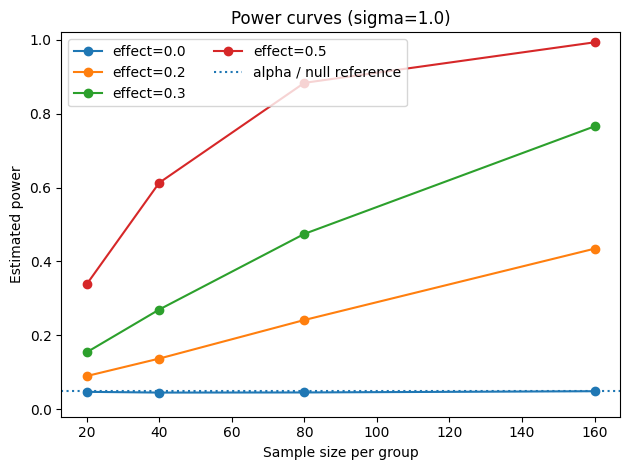

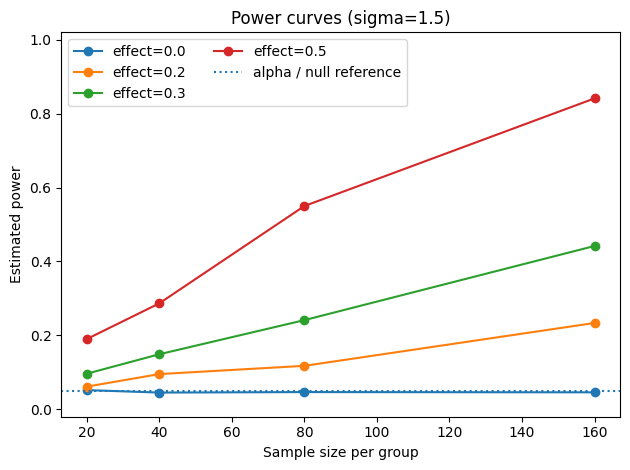

,n_per_group,sigma,effect,repetitions,alpha,rejections,estimated_power,mc_se
0,20,1.0,0.0,3000,0.05,142,0.047333,0.003877
1,40,1.0,0.0,3000,0.05,136,0.045333,0.003798
2,80,1.0,0.0,3000,0.05,137,0.045667,0.003811
3,160,1.0,0.0,3000,0.05,147,0.049000,0.003941
4,20,1.0,0.2,3000,0.05,270,0.090000,0.005225
5,40,1.0,0.2,3000,0.05,412,0.137333,0.006284
6,80,1.0,0.2,3000,0.05,725,0.241667,0.007816
7,160,1.0,0.2,3000,0.05,1304,0.434667,0.009050
8,20,1.0,0.3,3000,0.05,463,0.154333,0.006596
9,40,1.0,0.3,3000,0.05,810,0.270000,0.008106


Interpretation prompt: Compare sample size, noise, and effect size. At effect=0, check whether the false-positive rate is near alpha within Monte Carlo variability.


In [5]:
power_rng = np.random.default_rng(SEED + 20)
ns = [20, 40, 80, 160]
sigmas = [1.0, 1.5]
effects = [0.0, 0.2, 0.3, 0.5]
rows = []
for sigma in sigmas:
    for effect in effects:
        for n in ns:
            rejects = 0
            for _ in range(N_REPS):
                aa, bb = simulate_two_groups(n, effect, sigma, rng=power_rng)
                rejects += mean_difference_ci_welch(aa, bb)[3] < ALPHA
            power = rejects/N_REPS
            rows.append({'n_per_group':n,'sigma':sigma,'effect':effect,
                         'repetitions':N_REPS,'alpha':ALPHA,'rejections':rejects,
                         'estimated_power':power,
                         'mc_se':np.sqrt(power*(1-power)/N_REPS)})
power_df = pd.DataFrame(rows)
power_df.to_csv(RES_DIR/'power_results.csv', index=False)
for sigma in sigmas:
    for effect in effects:
        sub = power_df[(power_df.sigma==sigma)&(power_df.effect==effect)]
        plt.plot(sub.n_per_group, sub.estimated_power, marker='o', label=f'effect={effect}')
    plt.axhline(ALPHA, linestyle=':', label='alpha / null reference')
    plt.ylim(-0.02,1.02); plt.xlabel('Sample size per group'); plt.ylabel('Estimated power')
    plt.title(f'Power curves (sigma={sigma})'); plt.legend(ncol=2); plt.tight_layout()
    plt.savefig(FIG_DIR/f'power_curve_sigma_{str(sigma).replace(".","p")}.png', dpi=160); plt.show()
display(power_df)
print('Interpretation prompt: Compare sample size, noise, and effect size. At effect=0, check whether the false-positive rate is near alpha within Monte Carlo variability.')

## 6. Assumption-violating counterexample: heavy tails
The baseline assumes normally distributed observations. The counterexample uses Student-t errors with 3 degrees of freedom, scaled to have the requested standard deviation. This creates heavier tails than a normal distribution while retaining finite variance. Compare the rejection rate and interval coverage under a zero effect (Type I error) and a meaningful nonzero effect. This is a targeted counterexample, not proof that Welch inference always fails under heavy tails.

In [6]:
counter_rng = np.random.default_rng(SEED + 30)
ce_rows = []
for distribution in ['normal','heavy_tailed']:
    for effect in [0.0, 0.3]:
        n=40; sigma=1.0; rejected=0; covered=0; widths=[]
        for _ in range(N_REPS):
            aa, bb = simulate_two_groups(n, effect, sigma, rng=counter_rng, distribution=distribution)
            estimate, lower, upper, pv = mean_difference_ci_welch(aa, bb)
            rejected += pv < ALPHA
            covered += lower <= effect <= upper
            widths.append(upper-lower)
        ce_rows.append({'distribution':distribution,'n_per_group':n,'sigma':sigma,'true_effect':effect,
                        'repetitions':N_REPS,'alpha':ALPHA,'rejection_rate':rejected/N_REPS,
                        'coverage_rate':covered/N_REPS,'mean_ci_width':float(np.mean(widths))})
ce_df=pd.DataFrame(ce_rows)
ce_df.to_csv(RES_DIR/'counterexample_results.csv', index=False)
display(ce_df)
print('Interpretation prompt: Compare Type I error for effect=0, coverage for both effects, and average interval width. Explain what this one simulated design can and cannot establish.')

,distribution,n_per_group,sigma,true_effect,repetitions,alpha,rejection_rate,coverage_rate,mean_ci_width
0,normal,40,1.0,0.0,3000,0.05,0.059000,0.941,0.887915
1,normal,40,1.0,0.3,3000,0.05,0.259000,0.947,0.887392
2,heavy_tailed,40,1.0,0.0,3000,0.05,0.047000,0.953,0.864110
3,heavy_tailed,40,1.0,0.3,3000,0.05,0.322333,0.957,0.849679


Interpretation prompt: Compare Type I error for effect=0, coverage for both effects, and average interval width. Explain what this one simulated design can and cannot establish.


## 7. Independent verification and limitations
At minimum, independently verify one statistic using a second calculation. For example, compare the baseline estimate to `np.mean(b) - np.mean(a)` and verify whether the reported Welch interval contains the estimate. For power, independently recompute `rejections / repetitions` from `results/power_results.csv`.

**Limitations to address in your own report:** (1) synthetic results only reflect the chosen data-generating process; (2) independence and the distributional assumptions may fail in real data; (3) finite repetitions cause Monte Carlo error; (4) power is conditional on the assumed effect, noise, test, and sample size; (5) statistical significance does not by itself establish practical importance; (6) the heavy-tail counterexample is illustrative rather than universal.

## 8. Export and reproducibility
The notebook writes figures and CSV outputs to the project folders. Run all cells from a fresh kernel before submitting. Record your actual environment, inspect the generated files, complete the report and AI-use log honestly, and commit the checked version to GitHub. Do not claim a verification step you did not perform.